# Fake News Detection — Exploratory Data Analysis and Text Analysis

## Objective

This notebook explores the cleaned article dataset prepared in Notebook 1.

The focus is on understanding the characteristics of the text before building machine learning models. The analysis examines class balance, article length, vocabulary, common terms, n-grams, punctuation patterns, capitalisation, and the relationship between available metadata and the target label.

The purpose of this stage is to identify meaningful patterns that can guide the NLP modelling strategy without using the exploratory results as training information for the final classifier.

The primary modelling text remains the combined article title and body created in Notebook 1.

## 1. Analysis Environment

The notebook loads the prepared modelling dataset saved by Notebook 1.

Loading the saved dataset rather than relying on the previous notebook's live variables makes this notebook reproducible even when the Jupyter kernel is restarted.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


## 2. Project Paths

The project root is detected automatically so that the notebook does not depend on a machine-specific absolute path.

In [2]:
def find_project_root():
    current = Path.cwd().resolve()

    candidates = [
        current,
        current.parent,
        current.parent.parent,
    ]

    for candidate in candidates:
        if (
            (candidate / "data" / "processed").exists()
            and (candidate / "notebooks").exists()
            and (candidate / "src").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the Fake-News-Detection project root. "
        "Make sure this notebook is inside the project's notebooks folder."
    )


PROJECT_ROOT = find_project_root()

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

PROCESSED_DATA_PATH = (
    PROCESSED_DATA_DIR / "news_modeling_data.csv"
)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:")
print(PROJECT_ROOT)

print("\nPrepared dataset:")
print(PROCESSED_DATA_PATH)

Project root:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection

Prepared dataset:
C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\data\processed\news_modeling_data.csv


## 3. Load the Prepared Dataset

The dataset loaded here is the output of Notebook 1 after its quality-control process.

No additional duplicate removal or label correction is performed in this notebook. This keeps the data preparation decisions consistent across the project.

In [3]:
if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        "Prepared dataset was not found.\n"
        f"Expected file:\n{PROCESSED_DATA_PATH}\n\n"
        "Run Notebook 1 completely before starting Notebook 2."
    )

modeling_df = pd.read_csv(PROCESSED_DATA_PATH)

print("Prepared dataset loaded successfully.")
print(f"Shape: {modeling_df.shape}")

print("\nColumns:")
print(modeling_df.columns.tolist())

Prepared dataset loaded successfully.
Shape: (39100, 7)

Columns:
['title', 'text', 'subject', 'date', 'label', 'label_name', 'model_text']


In [4]:
required_columns = {
    "title",
    "text",
    "subject",
    "date",
    "label",
    "label_name",
    "model_text",
}

missing_columns = required_columns.difference(
    modeling_df.columns
)

if missing_columns:
    raise ValueError(
        f"Notebook 1 output is missing required columns: "
        f"{sorted(missing_columns)}"
    )

print("Notebook 1 output schema verified successfully.")

Notebook 1 output schema verified successfully.


## 4. Dataset Overview

A quick overview confirms the number of observations, target classes, and the basic structure of the prepared data before moving into text-specific analysis.

In [5]:
print("Dataset shape:")
print(modeling_df.shape)

print("\nClass distribution:")
display(
    modeling_df["label_name"]
    .value_counts()
    .rename_axis("label_name")
    .to_frame("count")
)

print("\nSample records:")
display(
    modeling_df[
        [
            "title",
            "subject",
            "label_name",
        ]
    ].head(5)
)

Dataset shape:
(39100, 7)

Class distribution:


,count
label_name,
True,21195
Fake,17905



Sample records:


,title,subject,label_name
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,News,Fake
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation,News,Fake
2,Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,News,Fake
3,Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),News,Fake
4,Pope Francis Just Called Out Donald Trump During His Christmas Speech,News,Fake


## 5. Class Balance

Class balance is reviewed again from the prepared modelling dataset.

The final machine learning evaluation will use metrics such as precision, recall, and F1-score rather than relying on accuracy alone. This is especially useful when class distributions are not perfectly equal.

In [6]:
class_distribution = (
    modeling_df["label_name"]
    .value_counts()
    .rename_axis("label_name")
    .reset_index(name="count")
)

class_distribution["percentage"] = (
    class_distribution["count"]
    / class_distribution["count"].sum()
    * 100
)

display(class_distribution)

,label_name,count,percentage
0,True,21195,54.207161
1,Fake,17905,45.792839


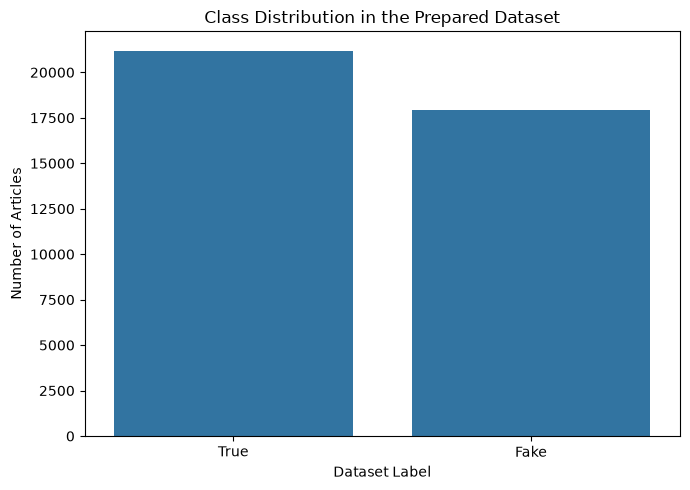

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\eda_class_distribution.png


In [7]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=class_distribution,
    x="label_name",
    y="count"
)

plt.title("Class Distribution in the Prepared Dataset")
plt.xlabel("Dataset Label")
plt.ylabel("Number of Articles")

plt.tight_layout()

path = FIGURES_DIR / "eda_class_distribution.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {path}")

## 6. Text Length Analysis

Article length can influence the number of textual features available to an NLP model.

Both character-level and word-level statistics are examined for the combined title-and-body text. The analysis is descriptive and does not assume that article length itself determines the target class.

In [8]:
modeling_df["model_text"] = (
    modeling_df["model_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

modeling_df["char_count"] = (
    modeling_df["model_text"].str.len()
)

modeling_df["word_count"] = (
    modeling_df["model_text"]
    .str.split()
    .str.len()
)

modeling_df["sentence_count"] = (
    modeling_df["model_text"]
    .str.count(r"[.!?]+")
    .clip(lower=1)
)

display(
    modeling_df[
        [
            "char_count",
            "word_count",
            "sentence_count",
        ]
    ].describe()
)

,char_count,word_count,sentence_count
count,39100.000000,39100.000000,39100.000000
mean,2504.629591,410.455115,21.973939
std,1943.571356,315.097541,18.038892
min,29.000000,2.000000,1.000000
25%,1347.000000,220.000000,11.000000
50%,2287.000000,378.000000,19.000000
75%,3162.000000,521.000000,29.000000
max,51892.000000,8148.000000,772.000000


## 7. Text Length by Class

The distributions are compared across the two labels to identify whether the dataset contains noticeable differences in article length.

These patterns are treated as dataset characteristics rather than evidence of a universal relationship between article length and misinformation.

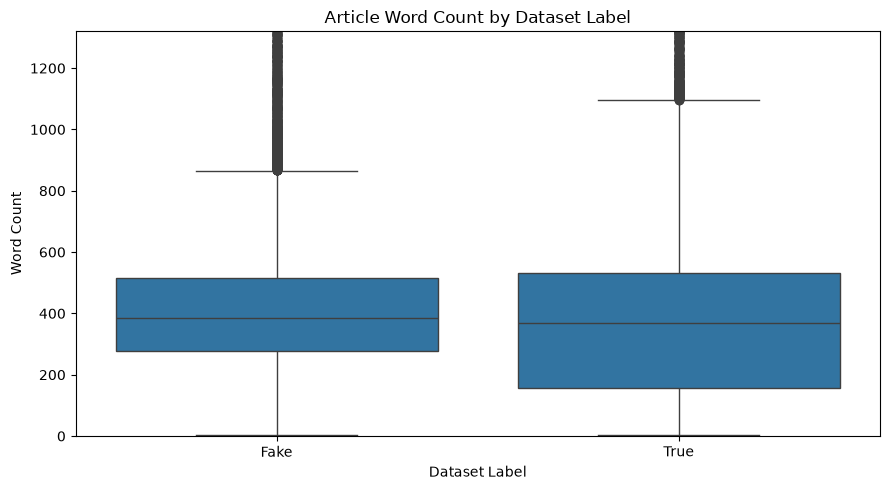

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\eda_word_count_by_class.png


In [9]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=modeling_df,
    x="label_name",
    y="word_count"
)

upper_limit = modeling_df["word_count"].quantile(0.99)

plt.ylim(0, upper_limit)

plt.title("Article Word Count by Dataset Label")
plt.xlabel("Dataset Label")
plt.ylabel("Word Count")

plt.tight_layout()

path = FIGURES_DIR / "eda_word_count_by_class.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {path}")

In [10]:
length_summary = (
    modeling_df
    .groupby("label_name")[
        [
            "char_count",
            "word_count",
            "sentence_count",
        ]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(length_summary)

char_count                  word_count                 \
                 mean  median      std       mean median     std   
label_name                                                         
Fake          2577.42  2291.0  2210.08     428.93  385.0  357.03   
True          2443.13  2281.0  1683.53     394.84  369.0  273.77   

           sentence_count                
                     mean median    std  
label_name                               
Fake                22.85   20.0  20.12  
True                21.23   18.0  16.03

## 8. Title-Level Analysis

News titles often contain strong lexical signals, so their length and vocabulary are examined separately from the full article body.

The title remains part of the primary `model_text` used later.

In [11]:
modeling_df["title_clean"] = (
    modeling_df["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

modeling_df["title_word_count"] = (
    modeling_df["title_clean"]
    .str.split()
    .str.len()
)

title_summary = (
    modeling_df
    .groupby("label_name")["title_word_count"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(title_summary)

,count,mean,median,std
label_name,,,,
Fake,17905,14.32,14.0,3.97
True,21195,9.95,10.0,1.70


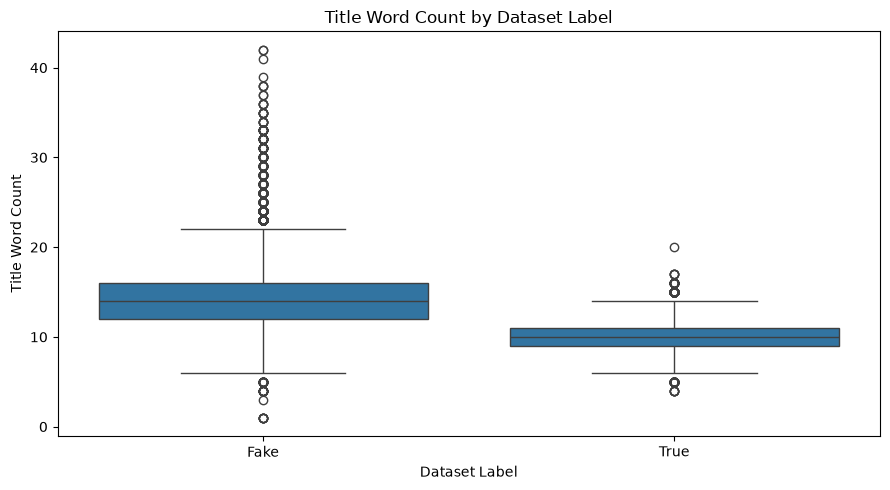

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\eda_title_length_by_class.png


In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=modeling_df,
    x="label_name",
    y="title_word_count"
)

plt.title("Title Word Count by Dataset Label")
plt.xlabel("Dataset Label")
plt.ylabel("Title Word Count")

plt.tight_layout()

path = FIGURES_DIR / "eda_title_length_by_class.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {path}")

## 9. Basic Text Characteristics

The next analysis looks at characteristics such as:

- uppercase characters
- punctuation
- numeric tokens
- whitespace
- alphabetic characters

These statistics can help understand the style of the source material and inform later preprocessing decisions.

In [13]:
def safe_text_stat(series, pattern):
    return (
        series
        .fillna("")
        .astype(str)
        .str.count(pattern)
    )


modeling_df["uppercase_count"] = (
    modeling_df["model_text"]
    .apply(lambda text: sum(char.isupper() for char in text))
)

modeling_df["punctuation_count"] = (
    modeling_df["model_text"]
    .apply(lambda text: sum(char in ".,!?;:'\"-()[]{}" for char in text))
)

modeling_df["digit_count"] = (
    modeling_df["model_text"]
    .apply(lambda text: sum(char.isdigit() for char in text))
)

modeling_df["uppercase_ratio"] = (
    modeling_df["uppercase_count"]
    / modeling_df["char_count"].replace(0, np.nan)
)

modeling_df["punctuation_ratio"] = (
    modeling_df["punctuation_count"]
    / modeling_df["char_count"].replace(0, np.nan)
)

display(
    modeling_df[
        [
            "uppercase_count",
            "punctuation_count",
            "digit_count",
            "uppercase_ratio",
            "punctuation_ratio",
        ]
    ].describe()
)

,uppercase_count,punctuation_count,digit_count,uppercase_ratio,punctuation_ratio
count,39100.000000,39100.000000,39100.000000,39100.000000,39100.000000
mean,106.254322,53.332046,15.906164,0.054490,0.021952
std,81.790638,52.317011,25.841298,0.055304,0.006474
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.000000,27.000000,2.000000,0.034030,0.018263
50%,91.000000,46.000000,9.000000,0.041852,0.020904
75%,129.000000,67.000000,21.000000,0.055073,0.024143
max,2832.000000,5021.000000,1396.000000,0.878788,0.187316


## 10. Style Characteristics by Class

These statistics are compared across labels as exploratory signals.

They are not treated as standalone classification rules. The purpose is to understand the dataset before the machine learning stage.

In [14]:
style_summary = (
    modeling_df
    .groupby("label_name")[
        [
            "uppercase_ratio",
            "punctuation_ratio",
            "digit_count",
        ]
    ]
    .mean()
    .round(4)
)

display(style_summary)

,uppercase_ratio,punctuation_ratio,digit_count
label_name,,,
Fake,0.0691,0.0221,17.3789
True,0.0421,0.0218,14.6620


## 11. Lightweight Text Normalisation for EDA

A separate lightweight representation is created for frequency analysis.

This representation is used only to count words and n-grams. It is not the final preprocessing pipeline used by the classifier.

The modelling pipeline in Notebook 3 will perform its own vectorisation after the train-validation split.

In [15]:
def normalise_for_frequency(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


modeling_df["eda_text"] = (
    modeling_df["model_text"]
    .apply(normalise_for_frequency)
)

print("Exploratory text representation created.")
display(
    modeling_df[
        ["model_text", "eda_text"]
    ].head(3)
)

Exploratory text representation created.


,model_text,eda_text
0,Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all A...,donald trump sends out embarrassing new year s eve message this is disturbing donald trump just couldn t wish all am...
1,Drunk Bragging Trump Staffer Started Russian Collusion Investigation House Intelligence Committee Chairman Devin Nun...,drunk bragging trump staffer started russian collusion investigation house intelligence committee chairman devin nun...
2,"Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’ On Friday, it was revealed...",sheriff david clarke becomes an internet joke for threatening to poke people in the eye on friday it was revealed th...


## 12. Vocabulary Size

Vocabulary size gives a basic indication of how varied the language is across the dataset.

The calculation is performed on the exploratory text representation and is not used as a model feature.

In [16]:
all_words = []

for text in modeling_df["eda_text"]:
    all_words.extend(text.split())

unique_words = set(all_words)

print(f"Total word tokens: {len(all_words):,}")
print(f"Unique vocabulary terms: {len(unique_words):,}")

Total word tokens: 16,252,669
Unique vocabulary terms: 111,930


## 13. Most Frequent Terms

The most frequent words provide an initial view of the language used in the dataset.

Very common functional words can dominate raw frequency counts, so a second analysis will use English stop-word removal.

In [17]:
unigram_vectorizer = CountVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=10000,
)

unigram_matrix = unigram_vectorizer.fit_transform(
    modeling_df["eda_text"]
)

unigram_counts = np.asarray(
    unigram_matrix.sum(axis=0)
).ravel()

unigram_terms = (
    unigram_vectorizer
    .get_feature_names_out()
)

unigram_frequency = pd.DataFrame(
    {
        "term": unigram_terms,
        "count": unigram_counts,
    }
).sort_values(
    "count",
    ascending=False
)

display(
    unigram_frequency.head(20)
)

,term,count
8981,the,877905
9080,to,475796
6115,of,381819
371,and,351833
4408,in,312180
8980,that,206181
6154,on,175294
3561,for,155034
4686,is,143644
9261,trump,136006


## 14. Frequent Content Words

Raw word frequency is useful but can be dominated by common grammatical words.

A stop-word-aware representation is therefore used to highlight more content-oriented terms. This analysis is exploratory and is not used to remove words from the final model automatically.

In [18]:
content_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=10000,
)

content_matrix = content_vectorizer.fit_transform(
    modeling_df["eda_text"]
)

content_counts = np.asarray(
    content_matrix.sum(axis=0)
).ravel()

content_terms = (
    content_vectorizer
    .get_feature_names_out()
)

content_frequency = pd.DataFrame(
    {
        "term": content_terms,
        "count": content_counts,
    }
).sort_values(
    "count",
    ascending=False
)

display(
    content_frequency.head(30)
)

,term,count
9288,trump,136006
7833,said,122798
6835,president,50044
6490,people,36800
8547,state,31271
7619,reuters,29091
5983,new,28685
4263,house,26775
2714,donald,26574
3860,government,25373


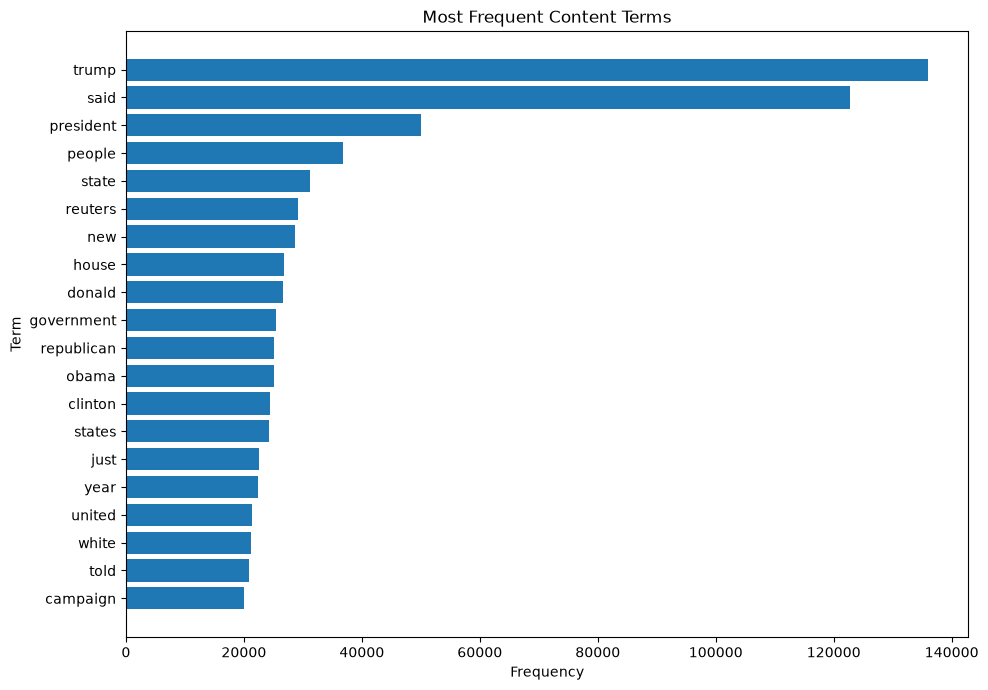

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\top_content_terms.png


In [19]:
top_terms = content_frequency.head(20).sort_values(
    "count",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_terms["term"],
    top_terms["count"]
)

plt.title("Most Frequent Content Terms")
plt.xlabel("Frequency")
plt.ylabel("Term")

plt.tight_layout()

path = FIGURES_DIR / "top_content_terms.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {path}")

## 15. Class-Specific Vocabulary

The vocabulary is now examined separately for the two dataset labels.

The goal is to identify terms that appear frequently within each class and understand whether the two groups contain visibly different lexical patterns.

In [20]:
fake_text = modeling_df.loc[
    modeling_df["label_name"] == "Fake",
    "eda_text"
]

true_text = modeling_df.loc[
    modeling_df["label_name"] == "True",
    "eda_text"
]

fake_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=10000,
)

true_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=10000,
)

fake_matrix = fake_vectorizer.fit_transform(fake_text)
true_matrix = true_vectorizer.fit_transform(true_text)

fake_counts = np.asarray(
    fake_matrix.sum(axis=0)
).ravel()

true_counts = np.asarray(
    true_matrix.sum(axis=0)
).ravel()

fake_frequency = pd.DataFrame(
    {
        "term": fake_vectorizer.get_feature_names_out(),
        "count": fake_counts,
    }
).sort_values(
    "count",
    ascending=False
)

true_frequency = pd.DataFrame(
    {
        "term": true_vectorizer.get_feature_names_out(),
        "count": true_counts,
    }
).sort_values(
    "count",
    ascending=False
)

print("Top terms in Fake-labelled articles:")
display(fake_frequency.head(20))

print("\nTop terms in True-labelled articles:")
display(true_frequency.head(20))

Top terms in Fake-labelled articles:


,term,count
9294,trump,76424
7824,said,24954
6882,president,21672
6530,people,21618
4936,just,18042
2732,donald,16145
6126,obama,15153
5261,like,14690
1607,clinton,14363
9593,video,12967



Top terms in True-labelled articles:


,term,count
7810,said,97844
9258,trump,59582
7587,reuters,28785
6775,president,28372
8504,state,21460
3861,government,18963
4256,house,17928
5937,new,17611
7456,republican,16774
8510,states,16574


## 16. Frequent Bigrams

Single words provide only limited context. Bigrams capture short two-word patterns and are useful for understanding phrase-level structure in the dataset.

These counts are exploratory only. The final NLP model will independently learn its vocabulary after the train-validation split.

In [21]:
bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(2, 2),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=15000,
)

bigram_matrix = bigram_vectorizer.fit_transform(
    modeling_df["eda_text"]
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigram_terms = (
    bigram_vectorizer
    .get_feature_names_out()
)

bigram_frequency = pd.DataFrame(
    {
        "bigram": bigram_terms,
        "count": bigram_counts,
    }
).sort_values(
    "count",
    ascending=False
)

display(
    bigram_frequency.head(30)
)

,bigram,count
3262,donald trump,24975
14036,united states,17025
14602,white house,14579
4999,hillary clinton,8291
7881,new york,8063
3939,featured image,7967
7999,north korea,6916
14429,washington reuters,6644
9253,president donald,6583
8902,pic twitter,4946


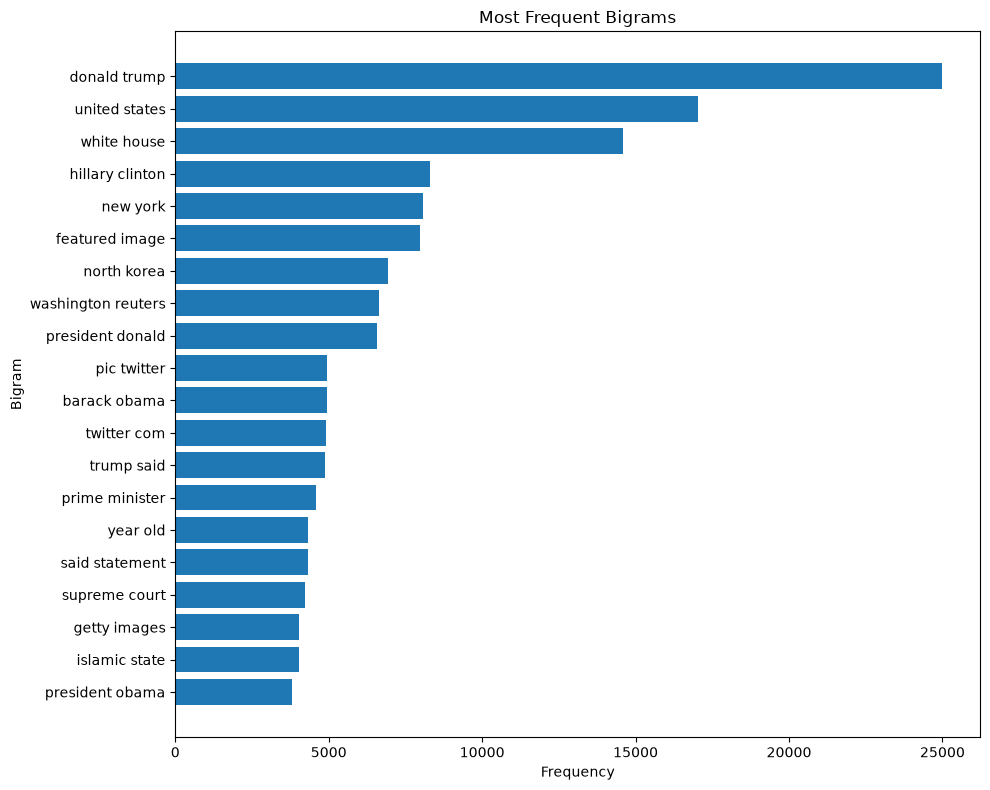

Figure saved to: C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\figures\top_bigrams.png


In [22]:
top_bigrams = bigram_frequency.head(20).sort_values(
    "count",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_bigrams["bigram"],
    top_bigrams["count"]
)

plt.title("Most Frequent Bigrams")
plt.xlabel("Frequency")
plt.ylabel("Bigram")

plt.tight_layout()

path = FIGURES_DIR / "top_bigrams.png"

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {path}")

## 17. Class-Specific Phrase Patterns

The most frequent bigrams are also examined separately for the two labels.

This helps identify whether phrase-level patterns may provide useful signals for the later TF-IDF model.

In [23]:
fake_bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(2, 2),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=15000,
)

true_bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(2, 2),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    max_features=15000,
)

fake_bigram_matrix = (
    fake_bigram_vectorizer.fit_transform(fake_text)
)

true_bigram_matrix = (
    true_bigram_vectorizer.fit_transform(true_text)
)

fake_bigram_counts = np.asarray(
    fake_bigram_matrix.sum(axis=0)
).ravel()

true_bigram_counts = np.asarray(
    true_bigram_matrix.sum(axis=0)
).ravel()

fake_bigram_frequency = pd.DataFrame(
    {
        "bigram": fake_bigram_vectorizer.get_feature_names_out(),
        "count": fake_bigram_counts,
    }
).sort_values(
    "count",
    ascending=False
)

true_bigram_frequency = pd.DataFrame(
    {
        "bigram": true_bigram_vectorizer.get_feature_names_out(),
        "count": true_bigram_counts,
    }
).sort_values(
    "count",
    ascending=False
)

print("Top Fake-labelled bigrams:")
display(fake_bigram_frequency.head(20))

print("\nTop True-labelled bigrams:")
display(true_bigram_frequency.head(20))

Top Fake-labelled bigrams:


,bigram,count
3276,donald trump,14835
3875,featured image,7966
5017,hillary clinton,5760
14494,white house,5465
13773,united states,4977
8907,pic twitter,4946
13710,twitter com,4926
4336,getty images,4022
9277,president obama,3624
7890,new york,3234



Top True-labelled bigrams:


,bigram,count
14145,united states,12048
3336,donald trump,10140
14646,white house,9114
14487,washington reuters,6641
8070,north korea,6212
9283,president donald,5867
7966,new york,4829
9435,prime minister,4153
11393,said statement,3895
5808,islamic state,3688


## 18. Subject and Label Relationship

The dataset contains subject metadata in addition to article text.

This analysis checks whether particular subjects are disproportionately represented in one label. This is important because metadata imbalance can create shortcuts that a model might exploit if those fields are included directly.

The primary classifier will therefore continue to focus on the article text.

In [24]:
subject_label_table = pd.crosstab(
    modeling_df["subject"].fillna("Unknown"),
    modeling_df["label_name"]
)

display(subject_label_table)

label_name,Fake,True
subject,,
Government News,531,0
News,9050,0
US_News,783,0
left-news,705,0
politics,6836,0
politicsNews,0,11216
worldnews,0,9979


In [25]:
subject_label_percentage = pd.crosstab(
    modeling_df["subject"].fillna("Unknown"),
    modeling_df["label_name"],
    normalize="index"
) * 100

display(
    subject_label_percentage.round(2)
)

label_name,Fake,True
subject,,
Government News,100.0,0.0
News,100.0,0.0
US_News,100.0,0.0
left-news,100.0,0.0
politics,100.0,0.0
politicsNews,0.0,100.0
worldnews,0.0,100.0


## 19. Dataset Composition Check

The previous analysis helps identify whether metadata fields are closely associated with the target.

This matters for model design: a classifier that performs well only because it learns dataset-specific metadata patterns may not generalise to new news sources.

For this reason, the primary modelling experiment will use `model_text` rather than directly feeding `subject` or `date` into the classifier.

## 20. Text Availability and Coverage

Before moving to model development, the completeness of the actual NLP input is verified once more.

Every row used for modelling should contain usable text.

In [26]:
text_quality_check = pd.DataFrame(
    {
        "metric": [
            "Rows",
            "Non-empty model text",
            "Empty model text",
            "Minimum word count",
            "Median word count",
            "Maximum word count",
        ],
        "value": [
            len(modeling_df),
            modeling_df["model_text"].str.strip().ne("").sum(),
            modeling_df["model_text"].str.strip().eq("").sum(),
            modeling_df["word_count"].min(),
            modeling_df["word_count"].median(),
            modeling_df["word_count"].max(),
        ],
    }
)

display(text_quality_check)

,metric,value
0,Rows,39100.0
1,Non-empty model text,39100.0
2,Empty model text,0.0
3,Minimum word count,2.0
4,Median word count,378.0
5,Maximum word count,8148.0


## 21. Saving Exploratory Results

The main frequency tables are saved as CSV reports so that the observations from this notebook can be reviewed later without rerunning the complete analysis.

In [27]:
content_frequency_path = (
    REPORTS_DIR / "top_content_terms.csv"
)

bigram_frequency_path = (
    REPORTS_DIR / "top_bigrams.csv"
)

fake_frequency_path = (
    REPORTS_DIR / "fake_class_terms.csv"
)

true_frequency_path = (
    REPORTS_DIR / "true_class_terms.csv"
)

fake_bigram_path = (
    REPORTS_DIR / "fake_class_bigrams.csv"
)

true_bigram_path = (
    REPORTS_DIR / "true_class_bigrams.csv"
)

content_frequency.to_csv(
    content_frequency_path,
    index=False
)

bigram_frequency.to_csv(
    bigram_frequency_path,
    index=False
)

fake_frequency.to_csv(
    fake_frequency_path,
    index=False
)

true_frequency.to_csv(
    true_frequency_path,
    index=False
)

fake_bigram_frequency.to_csv(
    fake_bigram_path,
    index=False
)

true_bigram_frequency.to_csv(
    true_bigram_path,
    index=False
)

print("EDA frequency reports saved successfully.")

EDA frequency reports saved successfully.


## 22. Final Validation

The final checks confirm that the dataset required for Notebook 3 is still intact.

No machine learning model has been trained in this notebook, and no exploratory vectoriser is reused for final model training.

In [28]:
required_model_columns = [
    "model_text",
    "label",
    "label_name",
]

for column in required_model_columns:
    assert column in modeling_df.columns

assert modeling_df["model_text"].notna().all()

assert (
    modeling_df["model_text"]
    .str.strip()
    .ne("")
    .all()
)

assert set(
    modeling_df["label"].unique()
).issubset({0, 1})

assert set(
    modeling_df["label_name"].unique()
).issubset({"Fake", "True"})

print("Final Notebook 2 validation checks passed.")

Final Notebook 2 validation checks passed.


## 23. Key Findings and Modelling Direction

This notebook explored the prepared dataset from both a general data-analysis and an NLP perspective.

The analysis covered:

- class distribution
- article and title length
- sentence and character statistics
- punctuation and capitalisation patterns
- vocabulary size
- frequent content terms
- class-specific vocabulary
- frequent bigrams
- class-specific bigrams
- subject distribution across labels
- text availability and quality

These observations provide context for the modelling stage.

The next step is to build a supervised NLP classification pipeline. The primary approach will use TF-IDF representations with word and/or n-gram features and compare multiple linear machine learning models.

Importantly, the exploratory vectorisers created in this notebook will not be reused for model training. Notebook 3 will create fresh train-validation splits and fit the text transformation only on the training data.

In [29]:
print("=" * 60)
print("NOTEBOOK 2 COMPLETED SUCCESSFULLY")
print("=" * 60)

print(f"\nDataset rows analysed: {len(modeling_df):,}")
print(f"Vocabulary size: {len(unique_words):,}")

print("\nClass distribution:")
print(
    modeling_df["label_name"]
    .value_counts()
)

print("\nSaved EDA outputs:")
for path in [
    content_frequency_path,
    bigram_frequency_path,
    fake_frequency_path,
    true_frequency_path,
    fake_bigram_path,
    true_bigram_path,
]:
    print(f"- {path}")

print("\nNotebook 3 can now use the prepared dataset for NLP model development.")

NOTEBOOK 2 COMPLETED SUCCESSFULLY

Dataset rows analysed: 39,100
Vocabulary size: 111,930

Class distribution:
label_name
True    21195
Fake    17905
Name: count, dtype: int64

Saved EDA outputs:
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\top_content_terms.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\top_bigrams.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\fake_class_terms.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\true_class_terms.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\fake_class_bigrams.csv
- C:\Users\SanskritiSingh\Desktop\AI_Projects\Fake-News-Detection\reports\true_class_bigrams.csv

Notebook 3 can now use the prepared dataset for NLP model development.
